# 01 — Préparer les entrées (Panel Lémanique 2023)

Objectif : construire le socle commun du projet à partir des waypoints GPS et des legs (déplacements) du **Panel Lémanique 2023 (PL23)**.

Deux jeux de données sont prévus :

- **`pl23`** (source de travail) : waypoints convertis une fois en dataset Parquet partitionné, traités par tranches ; les legs, identifiées par l'identifiant panel (`user_id_fors`), sont traduites en identifiant Motiontag (celui des waypoints) ;
- **`declic`** (rétrocompatibilité) : reproduit le traitement Déclic d'avant — lecture directe des CSV en mémoire, même identifiant dans les legs et les waypoints, ni conversion ni correspondance d'identifiants.

Ce notebook :

1. lit les waypoints (dataset Parquet pour `pl23`, CSV pour `declic`) ;
2. nettoie les points GPS (précision, doublons, vitesses) ;
3. lit les legs et, pour `pl23`, traduit l'identifiant panel en identifiant Motiontag, puis les enrichit : trip, motif, moment de la journée, questionnaire, marche qui suit la voiture ;
4. associe chaque waypoint à une leg par jointure temporelle ;
5. garde les legs voiture dont la destination est dans le périmètre d'étude ;
6. découpe les traces voiture en segments, retire les boucles et valide le format ReLUT ;
7. écrit les tables nécessaires aux étapes spatiales et temporelles, dont `legs_enriched.parquet` (une ligne par leg) et les traces de marche après la voiture ;
8. construit le **corpus commun de legs** (`legs/corpus_by_leg.parquet`) avec les filtres `leg_filters` du YAML : précision GPS, nombre de points, durée, distance parcourue, distance origine–destination, trou dans le cercle de destination, durée du trip, tunnels. Les méthodes temporelle (32) et spatiale (22) traitent exactement ces legs. L'effet de chaque filtre se visualise dans le notebook 21.

Il ne lance ni l'approche spatiale ni le modèle temporel.

Documentation complète (paramètres, sorties, rapports, dépannage) : `docs/01_prepare_inputs.md`.

## Paramètres

Modifier uniquement cette cellule, puis exécuter le notebook de haut en bas.

- `DATA_SOURCE` choisit le jeu de données : `"pl23"` (source de travail) ou `"declic"` (rétrocompatibilité). Tout ce qui dépend du jeu — chemins, mode de lecture, correspondance d'identifiants, dossier de sortie — est dans `DATASETS` : on peut passer de l'un à l'autre sans rien écraser.
- Les chemins sont relatifs à la racine du projet.
- Les seuils de nettoyage, de segmentation et de validation sont dans `config/full_waypoints.yaml`.

In [1]:
CONFIG_NAME = "full_waypoints.yaml"
DATA_SOURCE = "pl23"     # "pl23" (source de travail) ou "declic" (rétrocompatibilité)
RUN_FULL = True          # False : run réduit (MAX_PARTITIONS pour pl23, MAX_FILES/USERS/SEGMENTS pour declic)

DATASETS = {
    # Source de travail : conversion Parquet + traitement par tranches + correspondance d'identifiants.
    "pl23": {
        "waypoint_source": "parquet",
        "waypoint_glob": "Data/GPS/pl23/waypoints/*.csv",   # À ADAPTER au dossier des waypoints PL23
        "waypoint_parquet_dir": "Data/GPS/pl23/waypoints-parquet",
        "legs_file": "Data/GPS/pl23/20241120_dump_situee/241120_legs_nogeom.csv",
        "leg_source": "pl23_legs_parquet",                  # colonnes préréglées (user_id_fors, started_at…)
        # Legs en identifiant panel (CH3181), waypoints en UUID Motiontag : table de correspondance obligatoire
        "user_id_map_file": "Data/GPS/pl23/20241120_dump_situee/241120_user_statistics.csv",
        # Enrichissement des legs : trip, motif, moment, questionnaire, marche après la voiture
        "leg_enrichment": True,
        "map_track_trip_file": "Data/GPS/pl23/20241120_dump_situee/241120_map_track_trip_journey.csv",
        "trips_file": "Data/GPS/pl23/20241120_dump_situee/241120_trips.csv",
        "survey_file": "Data/GPS/pl23/EPFL_vague1_v4.csv",
        "output_dir": "outputs/pl23",
    },
    # Rétrocompatibilité : traitement Déclic d'avant, CSV lus en mémoire, même identifiant des deux côtés.
    "declic": {
        "waypoint_source": "csv",
        "waypoint_glob": "Data/GPS/declic/waypoints-sample/*.csv",
        "waypoint_parquet_dir": None,
        "legs_file": "Data/GPS/declic/cleaned-base/parquet/legs.parquet",
        "leg_source": "declic_legs_parquet",   # ou "declic_legs_export" pour un export CSV/Parquet avec géométrie
        "user_id_map_file": None,
        "leg_enrichment": False,
        "map_track_trip_file": None,
        "trips_file": None,
        "survey_file": None,
        "output_dir": "outputs/declic",
    },
}
USER_ID_MAP_LEGS_COL = "user_id_fors"            # pl23 : colonne de la table de correspondance présente dans les legs
USER_ID_MAP_WAYPOINTS_COL = "user_id_motiontag"  # pl23 : colonne présente dans les waypoints
CAR_MODES = ["Mode::Car", "Mode::Ecar"]

# pl23 uniquement (dataset Parquet)
N_PARTITIONS = 64        # fixé à la conversion ; le changer impose de reconvertir
GROUPS_PER_RUN = 4       # partitions traitées ensemble : moins = moins de RAM ; le changer recalcule toutes les tranches
FORCE_RERUN = False      # True : recalcule aussi les tranches déjà terminées (après une modification du code)
RUN_CONVERSION = False   # True : (re)lance la conversion CSV → Parquet (CSV déjà convertis sautés)
RUN_EQUIVALENCE_TEST = False  # True : vérifie que le traitement par tranches = lecture CSV directe, sur quelques CSV
EQUIVALENCE_TEST_FILES = 2

# Limites d'un run réduit (RUN_FULL = False)
MAX_PARTITIONS = 2       # pl23
MAX_FILES = 1            # declic
MAX_USERS = 50           # declic
MAX_SEGMENTS = 80        # declic

# Enrichissement des legs (pl23)
DROP_LEGS_WITHOUT_TRIP = True          # legs absentes de map_track_trip_journey retirées
LOCAL_TIMEZONE = "Europe/Zurich"       # tranche horaire et jour ; "UTC" pour reproduire l'étape 23
POST_CAR_WALK_MAX_GAP_MINUTES = 15     # écart max entre fin de la voiture et début de la marche
POST_CAR_WALK_MAX_DISTANCE_M = 2000    # longueur max de la marche retenue
WRITE_POST_CAR_WALK_WAYPOINTS = True   # traces de la marche : waypoints_post_car_walk.parquet

# Périmètre d'étude : la destination d'une leg voiture (son dernier waypoint apparié) doit être dans ce layer
STUDY_AREA_BOUNDARY_FILE = "Data/GIS/AGGLO_PERIMETRE_AVEC_LAC.gpkg"
STUDY_AREA_BOUNDARY_LAYER = "agglo_perimetre_avec_lac"
APPLY_STUDY_AREA_FILTER = True

# Boucles au niveau des segments (diagnostic) : distance début-fin toujours calculée dans segment_candidates.csv.
# Le filtrage des boucles se fait au niveau des legs par le corpus commun (leg_filters.min_origin_destination_distance_m) :
# laisser APPLY_LOOP_FILTER = False pour que les deux méthodes partent du même corpus.
LOOP_RADIUS_M = 100
APPLY_LOOP_FILTER = False

In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name in {"Notebooks", "notebooks"}:
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
PROJECT_ROOT

PosixPath('/Users/maximiliantrique/Documents/Projet_python/parking_search_prediction _livrable_new')

In [3]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from parking_search_prediction.config import load_config, output_path, resolve_path
from parking_search_prediction.partitioned import check_partitioned_equivalence
from parking_search_prediction.pipeline import prepare
from parking_search_prediction.waypoint_parquet import convert_waypoints_to_parquet, load_manifest

## Configuration

Charge le YAML puis applique les paramètres ci-dessus. Le tableau affiché est la configuration effectivement utilisée.

In [4]:
if DATA_SOURCE not in DATASETS:
    raise ValueError(f"DATA_SOURCE doit valoir l'une de {sorted(DATASETS)}")
dataset = DATASETS[DATA_SOURCE]
RAW_WAYPOINT_SOURCE = dataset["waypoint_source"]   # "parquet" pour pl23, "csv" pour declic
if RAW_WAYPOINT_SOURCE == "parquet" and not dataset["user_id_map_file"]:
    raise ValueError(f"{DATA_SOURCE} : user_id_map_file est obligatoire (legs et waypoints n'ont pas le même identifiant).")
if RAW_WAYPOINT_SOURCE == "parquet" and not dataset["waypoint_parquet_dir"]:
    raise ValueError(f"{DATA_SOURCE} : waypoint_parquet_dir est obligatoire pour le dataset Parquet.")

config = load_config(PROJECT_ROOT / "config" / CONFIG_NAME)
config["paths"].update(
    {
        "output_dir": dataset["output_dir"],
        "waypoint_glob": dataset["waypoint_glob"],
        "legs_file": dataset["legs_file"],
    }
)
if dataset["waypoint_parquet_dir"]:
    config["paths"]["waypoint_parquet_dir"] = dataset["waypoint_parquet_dir"]
else:
    config["paths"].pop("waypoint_parquet_dir", None)
config["raw_waypoints"]["source"] = RAW_WAYPOINT_SOURCE
config.setdefault("parquet_conversion", {})["n_partitions"] = N_PARTITIONS

config["leg_matching"]["source"] = dataset["leg_source"]
config["leg_matching"]["car_modes"] = CAR_MODES
config["leg_matching"]["user_id_map"] = (
    {
        "file": dataset["user_id_map_file"],
        "legs_id_col": USER_ID_MAP_LEGS_COL,
        "waypoints_id_col": USER_ID_MAP_WAYPOINTS_COL,
    }
    if dataset["user_id_map_file"]
    else None
)

config.setdefault("leg_enrichment", {}).update(
    {
        "enabled": bool(dataset["leg_enrichment"]),
        "map_track_trip_file": dataset["map_track_trip_file"],
        "trips_file": dataset["trips_file"],
        "drop_legs_without_trip": DROP_LEGS_WITHOUT_TRIP,
        "local_timezone": LOCAL_TIMEZONE,
        "add_survey": bool(dataset["survey_file"]),
    }
)
config["leg_enrichment"].setdefault("post_car_walk", {}).update(
    {
        "max_gap_minutes": POST_CAR_WALK_MAX_GAP_MINUTES,
        "max_walk_distance_m": POST_CAR_WALK_MAX_DISTANCE_M,
        "write_waypoints": WRITE_POST_CAR_WALK_WAYPOINTS,
    }
)
if dataset["survey_file"]:
    config.setdefault("pl23_survey", {})["survey_file"] = dataset["survey_file"]

config.setdefault("spatial_detection", {}).update(
    {
        "destination_boundary_file": STUDY_AREA_BOUNDARY_FILE,
        "destination_boundary_layer": STUDY_AREA_BOUNDARY_LAYER,
        "apply_study_area_filter": APPLY_STUDY_AREA_FILTER,
    }
)
config["segmentation"]["loop_radius_m"] = LOOP_RADIUS_M
config["segmentation"]["apply_loop_filter"] = APPLY_LOOP_FILTER

config["run"]["groups_per_run"] = GROUPS_PER_RUN
config["run"]["force_rerun"] = FORCE_RERUN
if RUN_FULL:
    config["run"].update({"max_files": None, "max_users": None, "max_segments": None, "max_partitions": None})
elif RAW_WAYPOINT_SOURCE == "parquet":
    # Par tranches, max_users / max_segments changeraient de sens d'une tranche à l'autre : on limite les partitions.
    config["run"].update({"max_files": None, "max_users": None, "max_segments": None, "max_partitions": MAX_PARTITIONS})
else:
    config["run"].update(
        {"max_files": MAX_FILES, "max_users": MAX_USERS, "max_segments": MAX_SEGMENTS, "max_partitions": None}
    )

pd.Series(
    {
        "data_source": DATA_SOURCE,
        "config": CONFIG_NAME,
        "waypoint_source": config["raw_waypoints"]["source"],
        "waypoint_glob": config["paths"]["waypoint_glob"],
        "waypoint_parquet_dir": config["paths"].get("waypoint_parquet_dir"),
        "legs_file": config["paths"]["legs_file"],
        "leg_source": config["leg_matching"]["source"],
        "user_id_map": (config["leg_matching"]["user_id_map"] or {}).get("file"),
        "output_dir": config["paths"]["output_dir"],
        "car_modes": config["leg_matching"]["car_modes"],
        "leg_enrichment": dataset["leg_enrichment"],
        "post_car_walk": f"≤ {POST_CAR_WALK_MAX_GAP_MINUTES} min, ≤ {POST_CAR_WALK_MAX_DISTANCE_M} m",
        "study_area_filter": APPLY_STUDY_AREA_FILTER,
        "loop_filter": f"{APPLY_LOOP_FILTER} ({LOOP_RADIUS_M} m)",
        "run": config["run"],
    },
    name="configuration",
)

data_source                                                          pl23
config                                                full_waypoints.yaml
waypoint_source                                                   parquet
waypoint_glob                               Data/GPS/pl23/waypoints/*.csv
waypoint_parquet_dir                      Data/GPS/pl23/waypoints-parquet
legs_file               Data/GPS/pl23/20241120_dump_situee/241120_legs...
leg_source                                              pl23_legs_parquet
user_id_map             Data/GPS/pl23/20241120_dump_situee/241120_user...
output_dir                                                   outputs/pl23
car_modes                                         [Mode::Car, Mode::Ecar]
leg_enrichment                                                       True
post_car_walk                                          ≤ 15 min, ≤ 2000 m
study_area_filter                                                    True
loop_filter                           

## Vérification des entrées

Contrôle rapide que tous les fichiers configurés existent avant de lancer quoi que ce soit. Une ligne ❌ indique un chemin à corriger dans `DATASETS` ou dans les paramètres.

In [ ]:
waypoint_files = sorted(PROJECT_ROOT.glob(config["paths"]["waypoint_glob"]))
checks = {
    "waypoints CSV": (len(waypoint_files) > 0, f"{len(waypoint_files)} fichier(s) pour {config['paths']['waypoint_glob']!r}"),
    "legs": (resolve_path(config, config["paths"]["legs_file"]).exists(), config["paths"]["legs_file"]),
    "périmètre": (resolve_path(config, STUDY_AREA_BOUNDARY_FILE).exists(), STUDY_AREA_BOUNDARY_FILE),
}
if config["leg_matching"]["user_id_map"]:
    map_file = config["leg_matching"]["user_id_map"]["file"]
    checks["correspondance user_id"] = (resolve_path(config, map_file).exists(), map_file)
if dataset["leg_enrichment"]:
    for name in ("map_track_trip_file", "trips_file", "survey_file"):
        if dataset[name]:
            checks[name] = (resolve_path(config, dataset[name]).exists(), dataset[name])
if RAW_WAYPOINT_SOURCE == "parquet":
    manifest_path = resolve_path(config, config["paths"]["waypoint_parquet_dir"]) / "_conversion_manifest.json"
    checks["dataset Parquet"] = (
        manifest_path.exists() or RUN_CONVERSION,
        "présent"
        if manifest_path.exists()
        else ("absent — sera créé par la conversion" if RUN_CONVERSION else "absent — mettre RUN_CONVERSION = True"),
    )

for name, (ok, detail) in checks.items():
    print(f"{'✅' if ok else '❌'} {name:<24} {detail}")
if waypoint_files:
    total_gb = sum(path.stat().st_size for path in waypoint_files) / 1e9
    print(f"\n{len(waypoint_files)} CSV de waypoints, {total_gb:.2f} GB — premier : {waypoint_files[0].name}")

## Conversion CSV → Parquet (`pl23`, une seule fois)

Sans objet pour `declic`, qui lit directement ses CSV.

Copie fidèle des CSV dans un dataset Parquet partitionné par utilisateur (`crc32(user_id) % N_PARTITIONS`) : tous les waypoints d'un utilisateur sont dans la même partition. Aucune ligne n'est filtrée ; l'identifiant et le timestamp restent du texte, les autres colonnes sont en float64. `source_file` et `source_row_number` sont ajoutées comme dans la lecture CSV, donc les `waypoint_id` sont identiques.

La conversion est reprenable : un CSV déjà converti (même taille, même date de modification) est sauté. Si rien n'a changé, la cellule affiche simplement le manifeste.

In [ ]:
manifest = None
if RAW_WAYPOINT_SOURCE == "parquet":
    if RUN_CONVERSION:
        manifest = convert_waypoints_to_parquet(config)
    else:
        try:
            manifest = load_manifest(config)
        except FileNotFoundError:
            print("Aucun dataset Parquet : mettre RUN_CONVERSION = True et relancer cette cellule.")
else:
    print(f"{DATA_SOURCE} : lecture directe des CSV (rétrocompatibilité), pas de conversion.")

if manifest:
    display(
        pd.Series(
            {
                key: manifest[key]
                for key in [
                    "manifest_id", "created_at", "total_rows", "total_users", "null_user_rows",
                    "non_empty_partitions", "total_csv_bytes", "total_parquet_bytes", "schema_warnings",
                ]
            },
            name="conversion",
        )
    )
    partition_rows = pd.Series({k: v["rows"] for k, v in manifest["partitions"].items() if k != "null"})
    display(partition_rows.describe().rename("lignes par partition"))

## Test d'équivalence (`pl23`)

À lancer avant le premier run complet. Sans objet pour `declic`. Le test convertit les `EQUIVALENCE_TEST_FILES` premiers CSV dans un dataset de test, exécute les deux modes dans des dossiers séparés (`<output_dir>/_equivalence_test/`) en forçant plusieurs tranches, puis compare tables et rapports JSON. Toute différence est listée et la cellule s'arrête en erreur.

In [ ]:
if RUN_EQUIVALENCE_TEST and RAW_WAYPOINT_SOURCE != "parquet":
    print(f"{DATA_SOURCE} : lecture directe des CSV, pas de test d'équivalence.")
elif RUN_EQUIVALENCE_TEST:
    try:
        equivalence = check_partitioned_equivalence(config, n_files=EQUIVALENCE_TEST_FILES)
    except Exception as exc:
        print(f"\n❌ Le test d'équivalence a échoué : {type(exc).__name__}: {exc}")
        raise
    display(pd.Series(equivalence, name="équivalence"))
else:
    print("Test d'équivalence désactivé (RUN_EQUIVALENCE_TEST = False).")

## Exécution

`prepare()` contient toute la logique reproductible. Chaque ligne affichée donne l'heure et la durée de l'étape qui vient de se terminer.

Pour `pl23`, les partitions sont traitées par tranches de `GROUPS_PER_RUN`. Avant la première tranche, l'étape « 0. contrôle utilisateurs » vérifie que les utilisateurs des waypoints ont des legs et arrête le run tout de suite sinon. Une tranche terminée est sautée si on relance avec les mêmes données et la même configuration (reprise après plantage ou interruption).

In [ ]:
prepare_summary = prepare(config)
pd.Series(prepare_summary, name="prepare")

In [ ]:
synthesis_path = output_path(config, "reports", "prepare_partitioned_summary.json")
if RAW_WAYPOINT_SOURCE == "parquet" and synthesis_path.exists():
    synthesis = json.loads(synthesis_path.read_text(encoding="utf-8"))
    display(pd.Series(synthesis["plan"], name="plan"))
    display(pd.Series(synthesis["user_overlap"], name="utilisateurs waypoints ↔ legs"))
    display(pd.DataFrame({name: check["ok"] for name, check in synthesis["checks"].items()}, index=["ok"]).T)
    if synthesis["aggregation_warnings"]:
        print("Avertissements d'agrégation :", *synthesis["aggregation_warnings"], sep="\n- ")
    display(pd.DataFrame(synthesis["runs"]).set_index("run"))

## Contrôles : nettoyage et appariement

`cleaning_report.json` détaille les points retirés (précision, doublons, invalides). `waypoint_leg_matching_summary.json` donne la part de waypoints appariés, les statuts d'appariement et, pour `pl23`, la traduction des identifiants (`user_id_map_*`).

In [ ]:
cleaning_report = json.loads(output_path(config, "reports", "cleaning_report.json").read_text(encoding="utf-8"))
display(pd.Series(cleaning_report, name="cleaning_report"))

matching_report = json.loads(
    output_path(config, "reports", "waypoint_leg_matching_summary.json").read_text(encoding="utf-8")
)
display(pd.Series(matching_report, name="matching_report"))

# Pour pl23, waypoints_caronly.parquet est un dossier (un fichier par tranche) :
# on n'en charge que la première partie pour l'aperçu, et une seule colonne pour les comptes.
caronly_path = output_path(config, "data", "waypoints_caronly.parquet")
preview_path = sorted(caronly_path.glob("part-*.parquet"))[0] if caronly_path.is_dir() else caronly_path
waypoints_caronly = pd.read_parquet(preview_path)
display(
    waypoints_caronly[
        ["waypoint_id", "source_user_id", "timestamp", "leg_id", "effective_mode", "lat", "lon", "speed_kmh"]
    ].head()
)
modes = pd.read_parquet(caronly_path, columns=["effective_mode"])["effective_mode"]
display(modes.value_counts(dropna=False).rename("waypoints"))

## Contrôles : enrichissement des legs et marche après la voiture

`legs_enriched.parquet` : une ligne par leg (clé `leg_id`) avec trip, motif (`trip_purpose`, `purpose_agg`), moment (`time_of_day_end_trip`, `weekday`, en `LOCAL_TIMEZONE`), variables du questionnaire et, pour les legs voiture, la leg suivante du trip et le résultat de l'appariement de la marche (`post_car_walk_reason`). Les traces de marche retenues sont dans `waypoints_post_car_walk.parquet` (`leg_id` = marche, `car_leg_id` = voiture qui précède). Ces tables se joignent aux sorties temporelles et spatiales par `leg_id`.

In [ ]:
enrichment_report = json.loads(output_path(config, "reports", "leg_enrichment_summary.json").read_text(encoding="utf-8"))
if not enrichment_report.get("leg_enrichment_enabled"):
    print(f"{DATA_SOURCE} : enrichissement des legs désactivé.")
else:
    display(pd.Series({k: v for k, v in enrichment_report.items() if not isinstance(v, dict)}, name="enrichissement"))
    display(pd.Series(enrichment_report["post_car_walk_reasons"], name="legs voiture — marche suivante"))
    legs_enriched = pd.read_parquet(output_path(config, "data", "legs_enriched.parquet"))
    car = legs_enriched[legs_enriched["effective_mode"].isin(CAR_MODES)]
    display(car["purpose_agg"].value_counts().rename("legs voiture par motif"))
    display(car.loc[car["post_car_walk_matched"], ["post_car_walk_gap_seconds", "post_car_walk_length_m", "post_car_walk_duration_seconds"]]
            .describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))

## Corpus commun de legs

Filtres de la section `leg_filters` du YAML (un seul endroit pour les deux méthodes). `in_corpus` : legs traitées par les méthodes temporelle et spatiale ; `excluded` : legs voiture du périmètre écartées, avec le premier filtre non vérifié. Pour choisir les valeurs, voir le notebook 21 (taille du corpus selon chaque filtre).

In [5]:
from parking_search_prediction.leg_corpus import load_corpus

display(pd.Series(config.get("leg_filters", {}), name="leg_filters (YAML)").to_frame())
corpus = load_corpus(config)
display(corpus["corpus_status"].value_counts().rename("corpus_status"))
display(corpus.loc[corpus["corpus_status"].eq("excluded"), "corpus_exclusion_reason"].value_counts().rename("premier filtre non vérifié"))
corpus.loc[corpus["corpus_status"].isin(["in_corpus", "excluded"]),
           ["corpus_n_points", "corpus_duration_s", "corpus_length_m", "corpus_od_distance_m", "corpus_window_max_gap_s",
            "corpus_trip_duration_s"]].describe(percentiles=[0.1, 0.5, 0.9]).round(1)

,leg_filters (YAML)
max_accuracy_m,10
min_leg_points,20
min_leg_duration_s,300
min_leg_length_m,500
min_origin_destination_distance_m,100
max_window_gap_s,120
max_trip_duration_s,18000
destination_window_radius_m,1000
exclude_tunnel_h3_destinations,True
tunnel_h3_resolution,8


corpus_status
not_car_leg           465516
outside_study_area    116215
in_corpus              55083
excluded               21016
no_car_waypoints        1370
Name: corpus_status, dtype: Int64

corpus_exclusion_reason
leg_too_short_duration          13304
window_gap_too_long              2936
too_few_points                   2289
destination_in_tunnel_h3          893
origin_destination_too_close      796
trip_too_long                     747
leg_too_short_length               51
Name: premier filtre non vérifié, dtype: Int64

,corpus_n_points,corpus_duration_s,corpus_length_m,corpus_od_distance_m,corpus_window_max_gap_s,corpus_trip_duration_s
count,76099.0,76099.0,76099.0,76099.0,76053.0,76099.0
mean,446.0,1072.3,12131.5,8180.9,56.4,2950.4
std,689.8,1815.4,21757.3,15637.5,789.6,5695.4
min,1.0,0.0,0.0,0.0,0.0,6.0
10%,44.0,187.0,1231.7,615.3,5.0,481.0
50%,233.0,710.0,6215.3,3911.8,14.0,1835.0
90%,1043.0,2164.0,26878.5,18528.9,68.0,5790.0
max,20744.0,87823.0,628424.9,449350.2,86959.0,601669.0


### Waypoints restant à chaque étape

Entonnoir des waypoints, des fichiers bruts jusqu'au corpus commun (relit les rapports de l'étape 01, rien n'est recalculé). Les pertes du corpus sont détaillées par premier filtre non vérifié : ce sont les waypoints des legs écartées.

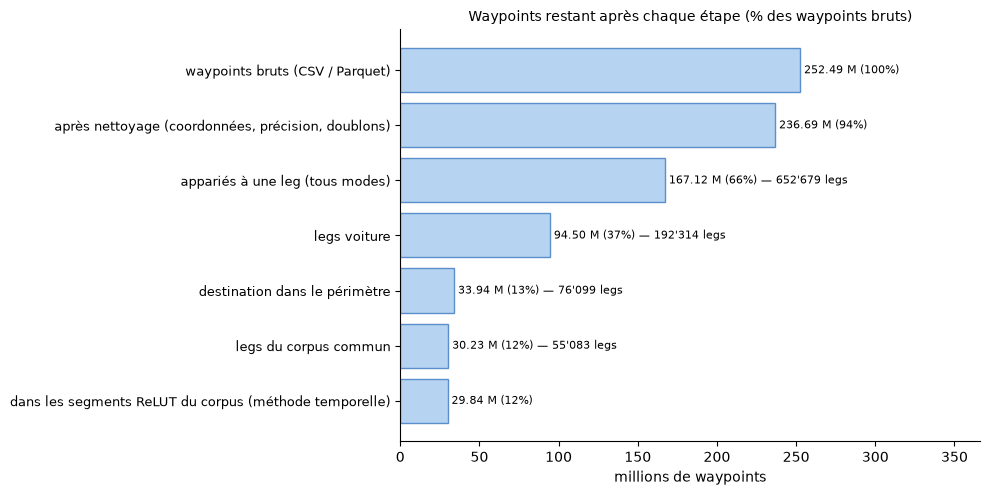

,etape,waypoints,legs,part_des_bruts,retires_a_cette_etape
0,waypoints bruts (CSV / Parquet),252489049,nan,100.0%,
1,"après nettoyage (coordonnées, précision, doublons)",236687985,nan,93.7%,15801064
2,appariés à une leg (tous modes),167116861,652679.000000,66.2%,69571124
3,legs voiture,94497904,192314.000000,37.4%,72618957
4,destination dans le périmètre,33939584,76099.000000,13.4%,60558320
5,legs du corpus commun,30229433,55083.000000,12.0%,3710151
6,dans les segments ReLUT du corpus (méthode temporelle),29836696,nan,11.8%,392737


retirés : coordonnées manquantes ou hors bornes             0
retirés : précision insuffisante (max_accuracy_m)    13882168
retirés : doublons                                    1918896
non appariés : hors de toute leg                     69026281
non appariés : legs qui se chevauchent                 536506
non appariés : utilisateur sans legs                     8337
Name: détail des waypoints retirés ou non appariés, dtype: int64

,premier_filtre_non_verifie,legs,waypoints des legs écartées
0,leg_too_short_duration,13304,1094679.0
1,window_gap_too_long,2936,934984.0
2,trip_too_long,747,694051.0
3,origin_destination_too_close,796,477086.0
4,destination_in_tunnel_h3,893,476592.0
5,too_few_points,2289,27042.0
6,leg_too_short_length,51,5717.0


In [6]:
from parking_search_prediction.leg_corpus import plot_waypoint_funnel, waypoint_funnel

funnel, corpus_losses = waypoint_funnel(config)
fig = plot_waypoint_funnel(funnel)
display(fig)
plt.close(fig)
display(funnel.style.format({"part_des_bruts": "{:.1%}"}))
display(pd.Series(funnel.attrs["details"], name="détail des waypoints retirés ou non appariés"))
corpus_losses.rename(columns={"waypoints": "waypoints des legs écartées"})

## Contrôles : périmètre d'étude

La destination d'une leg voiture est son **dernier waypoint apparié**. Le flag `spatial_destination_in_study_area` est calculé pour chaque leg, que `APPLY_STUDY_AREA_FILTER` soit activé ou non ; les deux dénominateurs (toutes les legs voiture / celles dans le périmètre) sont dans le rapport.

In [ ]:
study_area_report = json.loads(
    output_path(config, "reports", "spatial_study_area_filter_summary.json").read_text(encoding="utf-8")
)
pd.Series(study_area_report, name="spatial_study_area_filter")

## Contrôles : traces en boucle

Une trace est une boucle si son premier et son dernier waypoint sont à moins de `LOOP_RADIUS_M` mètres. Le flag `is_loop_segment` est dans `segment_candidates.csv` pour chaque trace retenue par la segmentation, que le filtre soit appliqué ou non.

In [ ]:
loop_filter_report = json.loads(output_path(config, "reports", "loop_filter_summary.json").read_text(encoding="utf-8"))
display(pd.Series(loop_filter_report, name="loop_filter"))

segment_candidates = pd.read_csv(output_path(config, "data", "segment_candidates.csv"))
display(
    segment_candidates.sort_values("loop_start_end_distance_m")[
        ["trip_candidate_id", "source_user_id", "distance_m", "loop_start_end_distance_m", "is_loop_segment"]
    ].head(10)
)

## Diagnostic de l'appariement (relecture des sorties, sans relancer)

Pourquoi des legs n'ont aucun waypoint apparié, et contrôle sur une fenêtre de dates. Les cellules relisent `waypoint_leg_assignments` (waypoints nettoyés) et, si `DIAG_SCAN_RAW`, le dataset Parquet des waypoints bruts (seulement l'identifiant et l'horodatage). Les comptages sont mis en cache dans `reports/01_diagnostics/` : la deuxième exécution est immédiate (`DIAG_RECOMPUTE = True` pour recalculer après un nouveau run). Jours **UTC**.

| Motif | Signification |
|---|---|
| `user_without_waypoints` | le participant n'a aucun waypoint |
| `no_raw_waypoints_that_day` | aucun waypoint brut ce jour-là : période non couverte ou application coupée |
| `all_waypoints_cleaned_that_day` | des points bruts ce jour-là, tous retirés par le nettoyage (précision…) |
| `only_overlapping_points` | des points dans la leg, tous en `overlapping_tracks` (legs qui se chevauchent) |
| `no_waypoint_in_interval` | des points ce jour-là, mais aucun pendant la leg (trou d'enregistrement, leg très courte) |

In [7]:
from parking_search_prediction.matching_diagnostics import plot_daily_coverage, run_matching_diagnostics, window_check

DIAG_SCAN_RAW = True       # lit aussi les waypoints bruts (distingue « pas de points » de « points nettoyés »)
DIAG_RECOMPUTE = False     # True après un nouveau run de l'étape 01

if not dataset["leg_enrichment"]:
    diagnostics = None
    print(f"{DATA_SOURCE} : diagnostic non disponible (il s'appuie sur legs_enriched, produit pour pl23).")
else:
    diagnostics = run_matching_diagnostics(config, scan_raw=DIAG_SCAN_RAW, recompute=DIAG_RECOMPUTE)
    display(pd.Series(diagnostics["summary"], name="appariement"))
    display(diagnostics["reasons"].style.format({"part_des_non_appariees": "{:.1%}"}))

legs                                      659200
matched_legs                              652679
unmatched_legs                              6521
raw_scanned                                 True
legs_period_utc         [2023-04-24, 2023-06-05]
waypoints_period_utc    [2023-04-24, 2023-06-05]
Name: appariement, dtype: object

,legs,dont_voiture,part_des_non_appariees
unmatched_reason,,,
user_without_waypoints,2415,672,37.0%
no_raw_waypoints_that_day,0,0,0.0%
all_waypoints_cleaned_that_day,2,0,0.0%
only_overlapping_points,2260,476,34.7%
no_waypoint_in_interval,1844,222,28.3%


date_from               2023-05-01
date_to                 2023-06-04
days                            35
legs                        586251
matched_legs                580411
clean_points             211927536
matched_points           150010075
raw_points               226011075
matched_legs_share        0.990038
matched_points_share      0.707837
Name: fenêtre 2023-05-01 → 2023-06-04, dtype: object

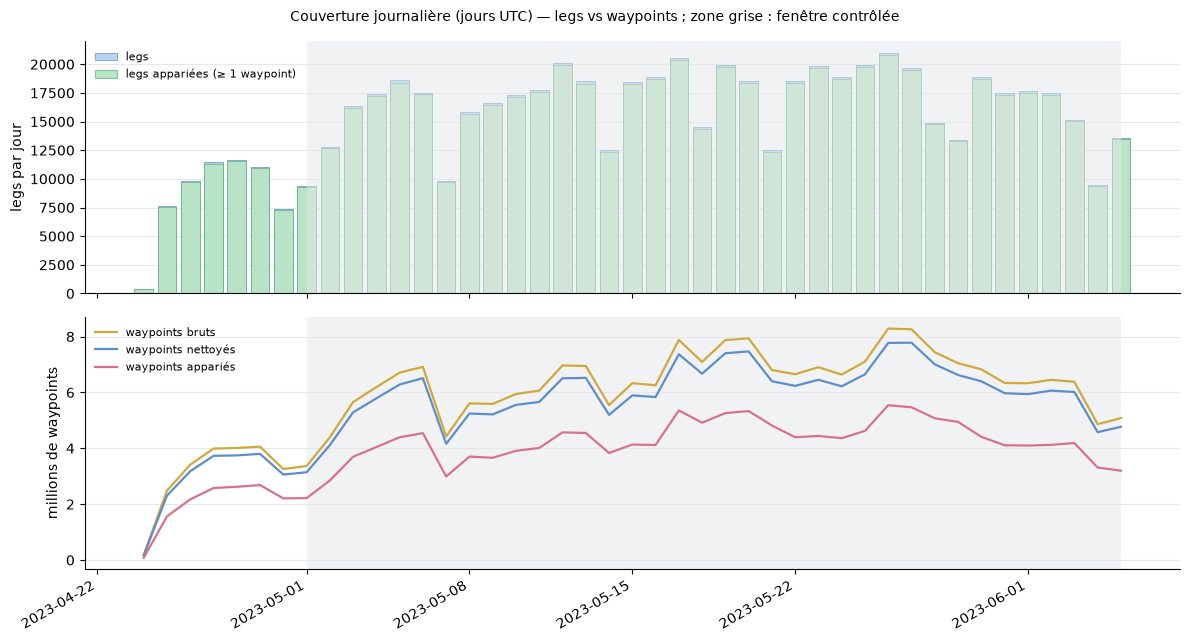

In [8]:
# Contrôle sur une fenêtre de dates (jours UTC inclus) ; un seuil non None déclenche un assert
DIAG_DATE_FROM = "2023-05-01"
DIAG_DATE_TO = "2023-06-04"
DIAG_MIN_MATCHED_LEGS_SHARE = None     # ex. 0.80
DIAG_MIN_MATCHED_POINTS_SHARE = None   # ex. 0.60

if diagnostics is not None:
    daily = diagnostics["daily"]
    check = window_check(daily, DIAG_DATE_FROM, DIAG_DATE_TO,
                         min_matched_legs_share=DIAG_MIN_MATCHED_LEGS_SHARE,
                         min_matched_points_share=DIAG_MIN_MATCHED_POINTS_SHARE)
    display(pd.Series(check, name=f"fenêtre {DIAG_DATE_FROM} → {DIAG_DATE_TO}"))
    fig = plot_daily_coverage(daily, DIAG_DATE_FROM, DIAG_DATE_TO)
    display(fig)
    plt.close(fig)
    daily.style.format({"matched_legs_share": "{:.1%}", "matched_points_share": "{:.1%}"})

## Suite

- `21_spatial_eda` : exploration spatiale des legs voiture ;
- `31_temporal_eda` : exploration des waypoints voiture avant le modèle temporel ;
- `32_temporal_detection` : modèle ReLUT sur `prepared_relut_points.parquet`.